In [1]:
import pandas as pd
import numpy as np


experiment_df = pd.read_csv("simulated_ab_test_data.csv")

print("Dataset shape:", experiment_df.shape)

display(experiment_df.head())

Dataset shape: (12393, 15)


,user_id,total_interactions,unique_games,total_hours,total_purchases,log_total_hours,cluster,group,treatment,baseline_probability,treatment_uplift,conversion_probability,click_probability,clicked,converted
0,5250,27,21,225.5,21,5.422745,2,A,0,0.12,0.02,0.12,0.12,0,0
1,76767,56,36,1227.0,36,7.113142,2,B,1,0.12,0.02,0.14,0.16,0,0
2,86540,97,82,255.0,82,5.545177,2,B,1,0.12,0.02,0.14,0.16,0,0
3,103360,10,10,0.0,10,0.000000,0,B,1,0.05,0.02,0.07,0.16,1,1
4,144736,9,8,0.1,8,0.095310,0,A,0,0.05,0.02,0.05,0.12,0,0


In [2]:
# Check column names
print("Columns:")
print(experiment_df.columns.tolist())

# Check missing values
print("\nMissing values:")
print(experiment_df.isnull().sum())

# Check experiment groups
print("\nGroup distribution:")
print(experiment_df["group"].value_counts())

# Check player clusters
print("\nCluster distribution:")
print(experiment_df["cluster"].value_counts().sort_index())

# Check conversion values
print("\nConversion values:")
print(experiment_df["converted"].value_counts())

# Check treatment assignment
print("\nTreatment assignment:")
print(experiment_df.groupby("group")["treatment"].unique())

Columns:
['user_id', 'total_interactions', 'unique_games', 'total_hours', 'total_purchases', 'log_total_hours', 'cluster', 'group', 'treatment', 'baseline_probability', 'treatment_uplift', 'conversion_probability', 'click_probability', 'clicked', 'converted']

Missing values:
user_id                   0
total_interactions        0
unique_games              0
total_hours               0
total_purchases           0
log_total_hours           0
cluster                   0
group                     0
treatment                 0
baseline_probability      0
treatment_uplift          0
conversion_probability    0
click_probability         0
clicked                   0
converted                 0
dtype: int64

Group distribution:
group
A    6265
B    6128
Name: count, dtype: int64

Cluster distribution:
cluster
0    6578
1    3945
2    1870
Name: count, dtype: int64

Conversion values:
converted
0    11425
1      968
Name: count, dtype: int64

Treatment assignment:
group
A    [0]
B    [1]
Name:

#Calculate conversion rates by cluster

In [3]:
# Calculate conversion statistics by cluster and experiment group

cluster_results = experiment_df.groupby(
    ["cluster", "group"]
).agg(
    total_players=("user_id", "count"),
    total_conversions=("converted", "sum"),
    conversion_rate=("converted", "mean")
).reset_index()

# Convert conversion rate into percentage
cluster_results["conversion_rate"] = (
    cluster_results["conversion_rate"] * 100
)

display(cluster_results.round(2))

,cluster,group,total_players,total_conversions,conversion_rate
0,0,A,3350,168,5.01
1,0,B,3228,226,7.00
2,1,A,1978,159,8.04
3,1,B,1967,179,9.10
4,2,A,937,94,10.03
5,2,B,933,142,15.22


In [4]:
# Pivot the results for easier comparison

conversion_comparison = cluster_results.pivot(
    index="cluster",
    columns="group",
    values="conversion_rate"
)

conversion_comparison.columns = [
    "Control_A_%",
    "Treatment_B_%"
]

# Calculate absolute treatment lift
conversion_comparison["Absolute_Lift_pp"] = (
    conversion_comparison["Treatment_B_%"] -
    conversion_comparison["Control_A_%"]
)

# Calculate relative treatment lift
conversion_comparison["Relative_Lift_%"] = (
    conversion_comparison["Absolute_Lift_pp"] /
    conversion_comparison["Control_A_%"]
) * 100

display(conversion_comparison.round(2))

,Control_A_%,Treatment_B_%,Absolute_Lift_pp,Relative_Lift_%
cluster,,,,
0,5.01,7.00,1.99,39.61
1,8.04,9.10,1.06,13.21
2,10.03,15.22,5.19,51.71


In [5]:
from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep
)
from statsmodels.stats.multitest import multipletests

cluster_tests = []

for cluster in sorted(experiment_df["cluster"].unique()):

    cluster_data = experiment_df[
        experiment_df["cluster"] == cluster
    ]

    control = cluster_data[cluster_data["group"] == "A"]
    treatment = cluster_data[cluster_data["group"] == "B"]

    # Conversion counts
    conversions_A = control["converted"].sum()
    conversions_B = treatment["converted"].sum()

    # Total players
    n_A = len(control)
    n_B = len(treatment)

    # Conversion rates
    rate_A = conversions_A / n_A
    rate_B = conversions_B / n_B

    # Absolute difference: Treatment - Control
    lift = rate_B - rate_A

    # Two-proportion Z-test
    z_stat, p_value = proportions_ztest(
        count=[conversions_B, conversions_A],
        nobs=[n_B, n_A]
    )

    # Newcombe 95% confidence interval
    ci_low, ci_high = confint_proportions_2indep(
        count1=conversions_B,
        nobs1=n_B,
        count2=conversions_A,
        nobs2=n_A,
        method="newcomb",
        compare="diff"
    )

    cluster_tests.append({
        "cluster": cluster,
        "control_rate": rate_A * 100,
        "treatment_rate": rate_B * 100,
        "absolute_lift_pp": lift * 100,
        "ci_lower_pp": ci_low * 100,
        "ci_upper_pp": ci_high * 100,
        "z_statistic": z_stat,
        "p_value": p_value
    })

cluster_test_results = pd.DataFrame(cluster_tests)

# Correct for multiple comparisons using Holm's method
cluster_test_results["adjusted_p_value"] = multipletests(
    cluster_test_results["p_value"],
    method="holm"
)[1]

cluster_test_results["significant"] = (
    cluster_test_results["adjusted_p_value"] < 0.05
)

display(cluster_test_results.round(4))

,cluster,control_rate,treatment_rate,absolute_lift_pp,ci_lower_pp,ci_upper_pp,z_statistic,p_value,adjusted_p_value,significant
0,0,5.0149,7.0012,1.9863,0.8390,3.1456,3.3939,0.0007,0.0021,True
1,1,8.0384,9.1002,1.0617,-0.6885,2.8164,1.1913,0.2335,0.2335,False
2,2,10.0320,15.2197,5.1877,2.1808,8.2041,3.3777,0.0007,0.0021,True


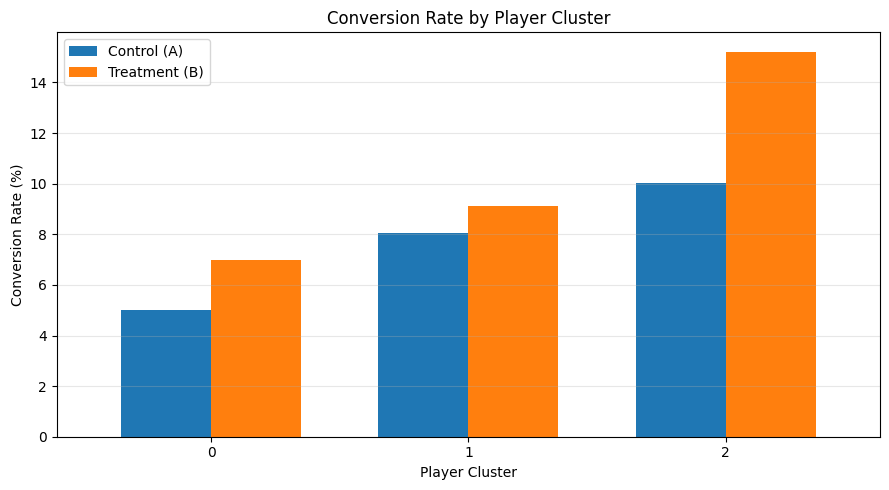

In [6]:
import matplotlib.pyplot as plt

plot_data = conversion_comparison[
    ["Control_A_%", "Treatment_B_%"]
]

ax = plot_data.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7
)

plt.title("Conversion Rate by Player Cluster")
plt.xlabel("Player Cluster")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=0)
plt.legend(["Control (A)", "Treatment (B)"])
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

We have established that the treatment effect is statistically significant in two clusters and not significant in one.

But we have not yet established that the treatment effects differ significantly between clusters.

For example, a significant result in Cluster 2 and a non-significant result in Cluster 1 does not automatically mean Cluster 2 responds significantly better.

To investigate that, we'll use logistic regression with an interaction term.

In [7]:
import statsmodels.formula.api as smf
import numpy as np
import pandas as pd

# Convert cluster into categorical variable
experiment_df["cluster"] = experiment_df["cluster"].astype("category")

# Fit logistic regression with interaction
model = smf.logit(
    formula="converted ~ treatment * C(cluster)",
    data=experiment_df
)

result = model.fit()

print(result.summary())

Optimization terminated successfully.
         Current function value: 0.269623
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:              converted   No. Observations:                12393
Model:                          Logit   Df Residuals:                    12387
Method:                           MLE   Df Model:                            5
Date:                Thu, 05 Nov 2026   Pseudo R-squ.:                 0.01643
Time:                        14:50:43   Log-Likelihood:                -3341.4
converged:                       True   LL-Null:                       -3397.2
Covariance Type:            nonrobust   LLR p-value:                 1.873e-22
                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------
Intercept                    -2.9413      0.079    -37.155      0.000      -3.

In [8]:
# Extract coefficients
coefficients = result.params

# Calculate odds ratios
odds_ratios = np.exp(coefficients)

# Calculate confidence intervals
confidence_intervals = np.exp(result.conf_int())

odds_ratio_results = pd.DataFrame({
    "Coefficient": coefficients,
    "Odds_Ratio": odds_ratios,
    "CI_Lower": confidence_intervals[0],
    "CI_Upper": confidence_intervals[1],
    "P_Value": result.pvalues
})

display(odds_ratio_results.round(4))

,Coefficient,Odds_Ratio,CI_Lower,CI_Upper,P_Value
Intercept,-2.9413,0.0528,0.0452,0.0617,0.0000
C(cluster)[T.1],0.5042,1.6556,1.3228,2.0721,0.0000
C(cluster)[T.2],0.7476,2.1120,1.6226,2.7490,0.0000
treatment,0.3548,1.4259,1.1607,1.7517,0.0007
treatment:C(cluster)[T.1],-0.2191,0.8032,0.5928,1.0882,0.1573
treatment:C(cluster)[T.2],0.1214,1.1291,0.7989,1.5958,0.4916


In [9]:
# Reduced model: no treatment interaction
reduced_model = smf.logit(
    formula="converted ~ treatment + C(cluster)",
    data=experiment_df
).fit()

# Full model: includes treatment interaction
full_model = result

# Likelihood ratio test
lr_statistic = 2 * (
    full_model.llf - reduced_model.llf
)

degrees_of_freedom = (
    full_model.df_model - reduced_model.df_model
)

from scipy.stats import chi2

lr_p_value = chi2.sf(
    lr_statistic,
    degrees_of_freedom
)

print("Likelihood Ratio Test")
print("---------------------")
print("LR Statistic:", round(lr_statistic, 4))
print("Degrees of Freedom:", int(degrees_of_freedom))
print("P-value:", round(lr_p_value, 6))

if lr_p_value < 0.05:
    print("Conclusion: Treatment effects differ significantly across clusters.")
else:
    print("Conclusion: No statistically significant evidence of treatment heterogeneity.")

Optimization terminated successfully.
         Current function value: 0.269780
         Iterations 7
Likelihood Ratio Test
---------------------
LR Statistic: 3.8932
Degrees of Freedom: 2
P-value: 0.14276
Conclusion: No statistically significant evidence of treatment heterogeneity.


# Hypotheses:
- H0: The treatment effect does not differ across player clusters.
- H1: The treatment effect differs across at least some player clusters.

Since 0.14276 is greater than 0.05, we fail to reject H0.

## Conclusion — Advanced Analysis

The advanced analysis investigated how personalized game recommendations performed across three player segments identified using KMeans clustering.

The segment-level analysis showed positive conversion improvements across all three clusters. Cluster 0 achieved a 1.99 percentage-point improvement, Cluster 1 achieved 1.06 percentage points, and Cluster 2 achieved the largest improvement of 5.19 percentage points.

After applying Holm correction for multiple comparisons, the improvements in Clusters 0 and 2 were statistically significant, whereas Cluster 1 did not demonstrate sufficient statistical evidence of improvement.

A logistic regression model with treatment-by-cluster interaction terms was subsequently developed. The treatment effect was positive and statistically significant in the reference segment (Cluster 0). However, neither individual interaction term was statistically significant.

Finally, a likelihood ratio test comparing the models with and without interaction terms produced a p-value of 0.14276. Therefore, the analysis did not establish statistically significant treatment heterogeneity across the three clusters.

Overall, the results suggest that personalized recommendations can improve simulated conversion performance across player segments. However, the evidence is insufficient to conclude that one particular segment benefits significantly more than another.

These findings are based on synthetically generated experimental outcomes and should be validated through a real randomized experiment before making production-level business decisions.

In [10]:
# Overall business performance

overall_results = experiment_df.groupby("group").agg(
    total_players=("user_id", "count"),
    conversions=("converted", "sum"),
    clicks=("clicked", "sum"),
    conversion_rate=("converted", "mean"),
    click_through_rate=("clicked", "mean")
)

display(overall_results.round(4))

control_rate = overall_results.loc["A", "conversion_rate"]
treatment_rate = overall_results.loc["B", "conversion_rate"]

absolute_lift = treatment_rate - control_rate

relative_lift = (
    absolute_lift / control_rate
) * 100

print("Absolute Conversion Lift:", round(absolute_lift * 100, 2), "pp")
print("Relative Conversion Lift:", round(relative_lift, 2), "%")

,total_players,conversions,clicks,conversion_rate,click_through_rate
group,,,,,
A,6265,421,749,0.0672,0.1196
B,6128,547,992,0.0893,0.1619


Absolute Conversion Lift: 2.21 pp
Relative Conversion Lift: 32.83 %


In [11]:
# Segment-level business opportunity

business_segments = conversion_comparison.copy()

business_segments["Priority"] = [
    "Moderate opportunity",
    "Further investigation needed",
    "Promising opportunity"
]

display(business_segments.round(2))

,Control_A_%,Treatment_B_%,Absolute_Lift_pp,Relative_Lift_%,Priority
cluster,,,,,
0,5.01,7.00,1.99,39.61,Moderate opportunity
1,8.04,9.10,1.06,13.21,Further investigation needed
2,10.03,15.22,5.19,51.71,Promising opportunity


In [12]:
# Business impact simulation

platform_users = 100000

expected_control_conversions = (
    platform_users * control_rate
)

expected_treatment_conversions = (
    platform_users * treatment_rate
)

additional_conversions = (
    expected_treatment_conversions -
    expected_control_conversions
)

print("Assumed Platform Users:", platform_users)

print(
    "Expected Control Conversions:",
    round(expected_control_conversions)
)

print(
    "Expected Treatment Conversions:",
    round(expected_treatment_conversions)
)

print(
    "Additional Conversions:",
    round(additional_conversions)
)

Assumed Platform Users: 100000
Expected Control Conversions: 6720
Expected Treatment Conversions: 8926
Additional Conversions: 2206


In [13]:
# Revenue impact estimation

average_revenue = 500  # INR

additional_revenue = (
    additional_conversions * average_revenue
)

print(
    "Assumed Revenue per Conversion: ₹",
    average_revenue
)

print(
    "Estimated Additional Revenue: ₹",
    round(additional_revenue)
)

Assumed Revenue per Conversion: ₹ 500
Estimated Additional Revenue: ₹ 1103184


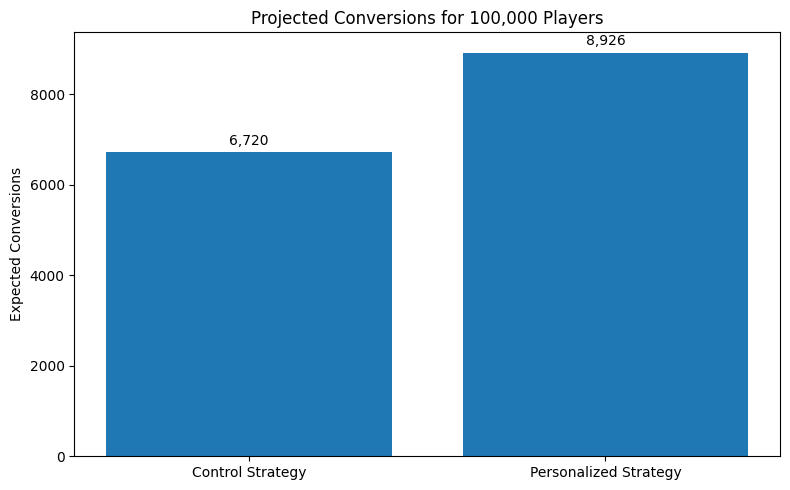

In [14]:
import matplotlib.pyplot as plt

categories = ["Control Strategy", "Personalized Strategy"]

conversion_counts = [
    expected_control_conversions,
    expected_treatment_conversions
]

plt.figure(figsize=(8, 5))

bars = plt.bar(categories, conversion_counts)

plt.title("Projected Conversions for 100,000 Players")
plt.ylabel("Expected Conversions")

plt.bar_label(
    bars,
    labels=[f"{value:,.0f}" for value in conversion_counts],
    padding=3
)

plt.tight_layout()
plt.show()

# Final Conclusion

This project demonstrates an end-to-end analytical workflow for understanding PC gaming behaviour and evaluating a personalized game recommendation strategy.

Using historical Steam interaction data, player-level behavioural features were engineered and KMeans clustering was applied to identify three distinct player segments.

A simulated randomized A/B experiment was then designed to compare generic recommendations against personalized recommendations.

The simulated treatment group achieved a conversion rate of 8.93%, compared with 6.72% in the control group, representing a 2.21 percentage-point absolute improvement.

Statistical hypothesis testing indicated a significant difference between the two groups. Further analysis examined segment-level performance using proportion tests, confidence intervals, logistic regression and likelihood ratio testing.

The results demonstrated positive simulated conversion improvements across all three player segments, although statistically significant improvements were established only for Clusters 0 and 2. The interaction analysis did not establish significant treatment heterogeneity.

Finally, a hypothetical business impact assessment demonstrated how conversion improvements could translate into additional conversions and potential revenue.

The project combines exploratory data analysis, unsupervised learning, experimental design, statistical inference and business analytics into one integrated data science workflow.

**The central takeaway:** Historical player behaviour can be used to develop meaningful player segments and design personalized recommendation experiments. However, real randomized experiments are necessary to validate their actual business effectiveness.